In [3]:
import numpy as np
from fit_file import X_sq
import matplotlib.pyplot as plt
import sympy as sp

In [4]:
###DATA INLEZEN
#DEEL 1 (PROEF 13)

achtergrond_1 = [2, 1, 2, 3, 3]
enkelbron_1 = [1147, 1246, 1248, 1227, 1272]
folie_1 = [89, 102, 99, 92, 84, 104]
papier_1= [81, 80, 78, 92, 79, 91, 78]
al_1mm_1 = [55, 37, 46, 40, 43, 68, 44, 47, 50, 38, 53]
al_2mm_1 = [24, 29, 37, 33, 36, 32, 37, 40, 42, 28, 38, 28, 28, 30, 34, 34]
al_4mm_1 = [35, 28, 23, 31, 28, 23, 27, 25, 20, 27, 22, 21, 29, 27, 26, 33]
pb_1mm_1 = [1, 2, 4, 4, 3]

#DEEL 2 (PROEF 22)

enkelbron_2 = [78, 79, 68, 72, 67, 76, 81]
al_01mm_2 = [70, 67, 76, 73, 63]
al_02mm_2 = [73, 67, 58, 74, 67]
al_03mm_2 = [56, 68, 52, 60, 52]
al_04mm_2 = [57, 55, 49, 49, 55]
al_05mm_2 = [55, 60, 45, 47, 59]
al_06mm_2 = [44, 53, 52, 53, 39]
al_07mm_2 = [54, 37, 53, 43, 49]
al_08mm_2 = [46, 58, 47, 37, 52]
al_09mm_2 = [37, 47, 55, 51, 39]
al_10mm_2 = [44, 37, 33, 51, 35]
al_15mm_2 = [26, 41, 32, 41, 44]
al_20mm_2 = [45, 24, 36, 34, 30]
al_25mm_2 = [35, 30, 27, 26, 34]
al_30mm_2 = [17, 39, 24, 32, 47, 36]
al_35mm_2 = [44, 29, 32, 30, 26, 28]
al_40mm_2 = [31, 22, 25, 26, 26, 22]
al_50mm_2 = [18, 19, 32, 27, 30, 23, 25]
al_60mm_2 = [15, 17, 26, 28, 19, 21, 17, 28]
al_70mm_2 = [18, 16, 23, 24, 24, 24, 34]
al_80mm_2 = [16, 25, 20, 20, 22, 20, 16, 23]
al_90mm_2 = [16, 25, 20, 20, 22, 20, 16, 23]


lijst_waarden = [enkelbron_2, al_01mm_2, al_02mm_2, al_03mm_2, al_04mm_2, al_05mm_2, al_06mm_2, al_07mm_2, al_08mm_2, al_09mm_2, al_10mm_2, al_15mm_2, al_20mm_2, al_25mm_2, al_30mm_2, al_35mm_2, al_40mm_2, al_50mm_2, al_60mm_2, al_70mm_2, al_80mm_2, al_90mm_2]

In [5]:

def fout_enkel(lijst):
    gem = np.mean(lijst)
    s = 1 / np.sqrt(len(lijst) - 1) * np.sqrt(np.sum((lijst - gem)**2)) #s
    return s / np.sqrt(len(lijst)) #s / sqrt(N)

def fout_tot(lijst, achtergrond_lijst, fout_lijst, fout_achtergrond):
    meting, achtergrond = sp.symbols('meting achtergrond')
    totaal = meting - achtergrond
    s_func = sp.sqrt((sp.diff(totaal, meting))**2 * fout_lijst**2 + (sp.diff(totaal, achtergrond))**2 * fout_achtergrond**2)
    s = s_func.subs([(meting, np.mean(lijst)), (achtergrond, np.mean(achtergrond_lijst))])
    return s

lijst_gem_proef2 = []#[arb eenh]
fouten_2 = []

gem_achtergrond = np.mean(achtergrond_1)
fout_achtergrond = fout_enkel(achtergrond_1)
#Itot = Igemeten - Iachtergrond


for i in lijst_waarden:
    gem = np.mean(i) - gem_achtergrond
    fout_meting = fout_enkel(i)
    echte_fout = fout_tot(i, achtergrond_1, fout_meting, fout_achtergrond)
    lijst_gem_proef2.append(gem)
    fouten_2.append(echte_fout)

lengtes = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.5, 2, 2.5, 3, 3.5, 4, 5, 6, 7, 8, 9] #[mm]

In [6]:
###fitten VOLLEDIG

gemiddeldes_fit = np.log(lijst_gem_proef2)
fouten_fit = np.array(fouten_2) / np.array(lijst_gem_proef2) #dx/x

def model(params, s):
    lnI0_hard, mu_hard, lnI0_zacht, mu_zacht = params
    
    I_hard = np.exp(lnI0_hard) * np.exp(-mu_hard * s)
    I_zacht = np.exp(lnI0_zacht) * np.exp(-mu_zacht * s)
    
    return np.log(I_hard + I_zacht)

x = np.array(lengtes).astype(float)
dx = np.zeros_like(x, dtype = float)
y = np.array(gemiddeldes_fit).astype(float)
dy = np.array(fouten_fit).astype(float)

params_names = ["lnhard", "muhard", "lnzacht", "muzacht"]
#X_sq(data = ((x, dx), (y, dy)), param_names = params_names, initial_guess = (3.5, 0.05, 3.8, 0.6), model = model, PLOT = False)

In [7]:
muhard = 0.06563463
muzacht = 1.54590567
lnhard = 3.55746620
lnzacht = 3.68368046

I0_1 = np.exp(lnzacht)
I0_2 = np.exp(lnhard)

x = np.linspace(0, 10, 1000)
#fig, ax = plt.subplots()

I27 = I0_2 * np.exp(-muhard * x)
I60 = I0_1 * np.exp(-muzacht * x)
Ibeide = I27 + I60

#ax.plot(x, np.log(I27), color = 'green')
#ax.plot(x, np.log(I60), color = "blue")
#ax.plot(x, np.log(Ibeide), color = "orange")
#
#ax.errorbar(lengtes, gemiddeldes_fit, yerr = fouten_fit, fmt = "o", color = 'black', capsize = 2)
#ax.set_ylim(2.75, 4.5)


---------START--------------------------------------------------------------------------------------------------


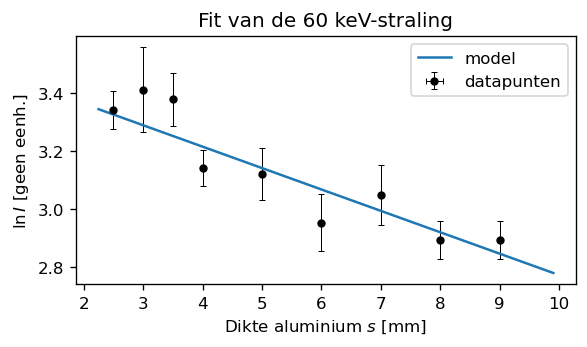

For parameter ln60     :     Minimum at       3.50924576     ;     68% CI = [      3.46978013,       3.54871139]
For parameter mu60     :     Minimum at       0.07361933     ;     68% CI = [      0.06707412,       0.08016455]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min           6.48464431
Reduced χ² value       :     χ²_red           0.92637776
P-value                :     p-value          0.48443045


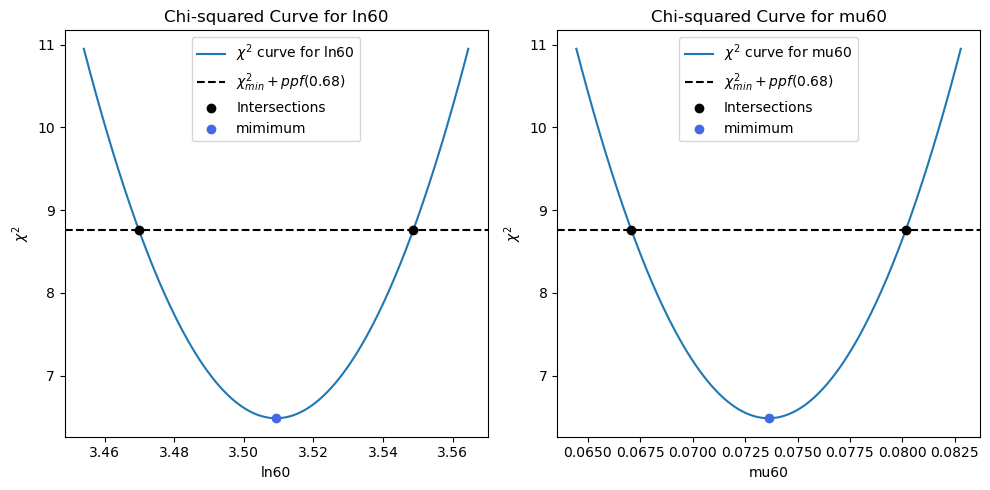

----------END---------------------------------------------------------------------------------------------------



In [8]:
###FITTEN RECHTES
###rechte 60 keV → vanaf s = 2.5mm → [13:]

def model_60keV(params, s):
    ln60, mu60 = params
    return ln60 - mu60 * s

param_names = ["ln60", "mu60"]

x = np.array(lengtes[13:]).astype(float)
dx = np.zeros_like(x, float)
y = np.array(gemiddeldes_fit[13:]).astype(float)
dy =np.array(fouten_fit[13:]).astype(float)

X_sq(((x, dx), (y, dy)), param_names, (3.6, 0.06), model_60keV, graf1_x_label= r'Dikte aluminium $s$ [mm]', graf1_y_label=r'$\ln I$ [geen eenh.]', graf1_title= "Fit van de 60 keV-straling", PLOT = True)


---------START--------------------------------------------------------------------------------------------------


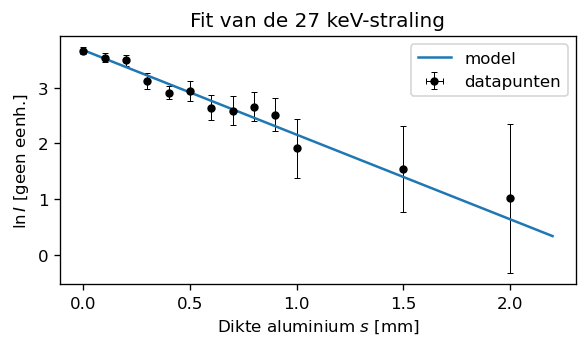

For parameter ln27     :     Minimum at       3.67082689     ;     68% CI = [      3.61526368,       3.72639011]
For parameter mu27     :     Minimum at       1.51670532     ;     68% CI = [      1.33927751,       1.69413315]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min           5.49827783
Reduced χ² value       :     χ²_red           0.49984344
P-value                :     p-value          0.90466025


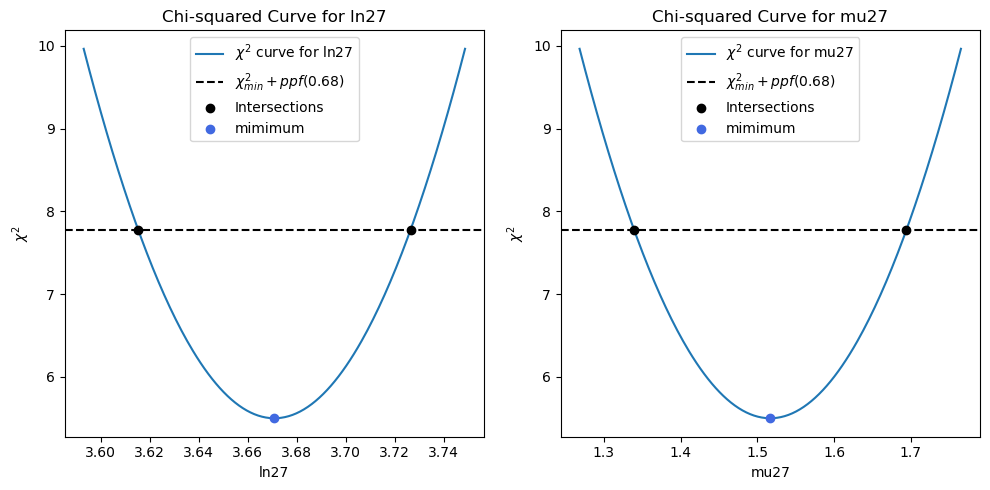

----------END---------------------------------------------------------------------------------------------------

0.03946563000000003 0.006545209999999996


In [10]:
###rechte 27keV = gem_fit - gefitte recht ([:13])
#model en waarden en fouten

ln60 = 3.50924576
mu60 = 0.07361933
dmu60 = mu60 - 0.06707412
dln60 = ln60 - 3.46978013

def model_27keV(params, s):
    ln27, mu27 = params
    return ln27 - mu27 * s

def fout_27(lnI60, mu60, dlnI, dmu, waarde60, dwaarde, s): #waarde komt uit lijst_gem_proef 2 en dwaarde uit fouten_2
    lnI, mu, waarde = sp.symbols('lnI mu waarde')
    I27 = sp.log(waarde - (sp.exp(lnI) * sp.exp(-mu * s)))
    s_func = sp.sqrt((sp.diff(I27, lnI))**2 * dlnI**2 + (sp.diff(I27, mu))**2 * dmu**2 + sp.diff(I27, waarde)**2 * dwaarde**2)
    s = s_func.subs([(lnI, lnI60), (mu, mu60), (waarde, waarde60)])
    return s

waarden_27 = np.array([])
fout_waarden_27 = np.array([])

for i in range(len(gemiddeldes_fit[:13])):
    w = np.log(lijst_gem_proef2[i] - (np.exp(ln60) * np.exp(-mu60 * lengtes[i])))
    waarden_27 = np.append(waarden_27, w)
    fout_waarden_27 = np.append(fout_waarden_27, fout_27(ln60, mu60, dln60, dmu60, lijst_gem_proef2[i], fouten_2[i], lengtes[i]))

#fit
param_names = ["ln27", "mu27"]
x = np.array(lengtes[:13]).astype(float)
dx = np.zeros_like(x)
y = waarden_27.astype(float)
dy = fout_waarden_27.astype(float)

X_sq(((x, dx), (y, dy)), param_names, (3.7, 1.5), model_27keV, graf1_x_label= r'Dikte aluminium $s$ [mm]', graf1_y_label=r'$\ln I$ [geen eenh.]', graf1_title= "Fit van de 27 keV-straling", PLOT = True)
print(dln60, dmu60)

0.05556320999999986 0.17742780999999996


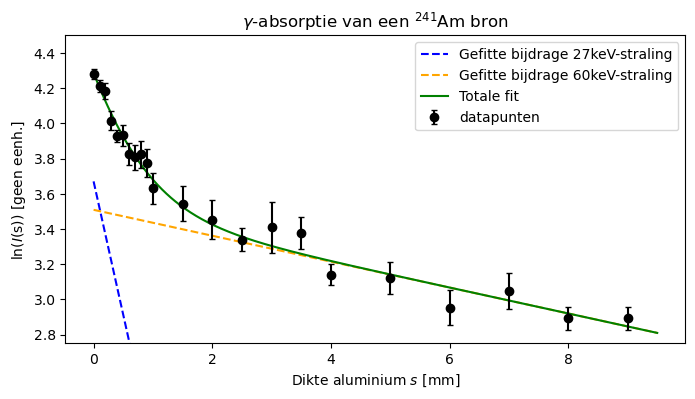

In [15]:
###FINALE RESULTAAT plotten

ln27 = 3.67082689
mu27 = 1.51670532
dln27 = ln27 - 3.61526368
dmu27 = mu27 - 1.33927751

fig, ax = plt.subplots(figsize = (8, 4))
x = np.linspace(0, 9.5, 1000)
I27 = np.exp(ln27) * np.exp(-mu27 * x)
I60 = np.exp(ln60) * np.exp(-mu60 * x)

ax.plot(x, np.log(I27), color = 'blue', linestyle = '--', label = r"Gefitte bijdrage 27keV-straling")
ax.plot(x, np.log(I60), color = 'orange', linestyle = '--', label = r"Gefitte bijdrage 60keV-straling")
ax.plot(x, np.log(I27 + I60), color = 'green', label = r"Totale fit")
ax.errorbar(lengtes, gemiddeldes_fit, yerr = fouten_fit, fmt = "o", color = 'black', capsize = 2, label = "datapunten")
ax.set_ylim(2.75, 4.5)
ax.legend()
ax.set_xlabel(r"Dikte aluminium $s$ [mm]")
ax.set_ylabel(r"ln($I$(s)) [geen eenh.]")
ax.set_title(r"$\gamma$-absorptie van een $^{241}$Am bron")
print(dln27, dmu27)

In [10]:
###DEEL 1 
achtergrond_1 = [2, 1, 2, 3, 3]
enkelbron_1 = [1147, 1246, 1248, 1227, 1272]
folie_1 = [89, 102, 99, 92, 84, 104]
papier_1= [81, 80, 78, 92, 79, 91, 78]
al_1mm_1 = [55, 37, 46, 40, 43, 68, 44, 47, 50, 38, 53]
al_2mm_1 = [24, 29, 37, 33, 36, 32, 37, 40, 42, 28, 38, 28, 28, 30, 34, 34]
al_4mm_1 = [35, 28, 23, 31, 28, 23, 27, 25, 20, 27, 22, 21, 29, 27, 26, 33]
pb_1mm_1 = [1, 2, 4, 4, 3]

gem_achtergrond = np.mean(achtergrond_1)
fout_achtergrond = fout_enkel(achtergrond_1)

alle_waarden = [achtergrond_1, enkelbron_1, folie_1, papier_1, al_1mm_1, al_2mm_1, al_4mm_1, pb_1mm_1]
alle_gem = []
alle_fouten_ZONDERACHTERGROND = []
alle_fouten = []
for i in alle_waarden:
    alle_gem.append(np.mean(i))
    alle_fouten_ZONDERACHTERGROND.append(fout_enkel(i))
    alle_fouten.append(fout_tot(i, achtergrond_1, fout_enkel(i), fout_achtergrond))

print(alle_gem, alle_fouten_ZONDERACHTERGROND, gem_achtergrond, fout_achtergrond)

[2.2, 1228.0, 95.0, 82.71428571428571, 47.36363636363637, 33.125, 26.5625, 2.8] [0.3741657386773941, 21.47323915947475, 3.2249030993194205, 2.3064535311071115, 2.704449960117003, 1.2578917547494564, 1.0526504247216482, 0.58309518948453] 2.2 0.3741657386773941
